# Parte I: análise estrutural

Nesta parte, analisamos as ligações entre os produtos da base de jogos da Amazon. Dois produtos estão ligados quando foram avaliados pelos mesmos usuários. O peso $w$ da ligação indica quantos usuários avaliaram os dois produtos.

Usamos o grafo $G = (V, E, w)$ e mantemos apenas as ligações com peso $w \ge 2$. Esse recorte é chamado de *backbone*. Depois, selecionamos a maior componente conexa, chamada de LCC: o maior grupo em que é possível chegar de um produto a qualquer outro seguindo as ligações.

A base também contém consoles e acessórios. Por isso, usamos a palavra “produto” nas explicações.

In [1]:
import os, sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from IPython.display import Markdown, display

from src.comum import config
from src.comum.carga import carregar_grafo_analise, ler_tamanhos_componentes
from src.comum.exportacao import escrever_tabela, formatar_markdown
from src.comum.grafo import restringir_arestas
from src.parte1.topologia import (
    calcular_ccdf, calcular_clusterizacao_local, calcular_densidade, calcular_forcas,
    calcular_graus, contar_triangulos_por_vertice, distribuir_graus,
    resumir_graus,
)
from src.comum.validacao import conferir_clusterizacao, medir_distancias_exatas
from src.parte1.distancias import calcular_distancias_exatas
from src.comum.visualizacao import desenhar_subgrafo, plotar_distribuicao_graus, salvar_figura

DIR_RESULTADOS = config.RAIZ / "results"
DIR_RESULTADOS.mkdir(exist_ok=True)
DIR_IMAGENS = config.RAIZ / "imagens"
grafo = carregar_grafo_analise(config.DIR_PROCESSADO)
n, m = len(grafo.adjacencia), len(grafo.pesos)
print(f"LCC: |V| = {n:,}  |E| = {m:,}")

LCC: |V| = 21,284  |E| = 320,742


## 1. Componentes conexas

Primeiro, contamos as componentes antes de selecionar a maior delas. Consideramos os 36.626 produtos do grafo antes de selecionar a maior componente.

Uma componente é um grupo de vértices ligados por caminhos. Um produto que não tem nenhuma ligação com peso $w \ge 2$ fica isolado e conta como uma componente de tamanho 1.

In [2]:
with open(config.DIR_PROCESSADO / "componentes.csv", encoding="utf-8") as fluxo:
    tamanhos = ler_tamanhos_componentes(fluxo)
total_componentes = sum(tamanhos.values())
total_vertices = sum(t * q for t, q in tamanhos.items())
display(Markdown(formatar_markdown(["tamanho", "quantidade"], tamanhos.items())))
print(f"componentes: {total_componentes:,}  |  vértices: {total_vertices:,}  |  "
      f"LCC = {max(tamanhos) / total_vertices:.1%} dos jogos")

| tamanho | quantidade |
|---|---|
| 21284 | 1 |
| 6 | 2 |
| 5 | 5 |
| 4 | 6 |
| 3 | 34 |
| 2 | 251 |
| 1 | 14677 |

componentes: 14,976  |  vértices: 36,626  |  LCC = 58.1% dos jogos


Encontramos **14.976 componentes**. A maior tem **21.284 produtos**, o que corresponde a **58,1%** dos 36.626 produtos. As outras componentes têm no máximo 6 vértices.

Também encontramos **14.677 produtos isolados**. Eles não têm ligação com outro produto que atenda ao mínimo de dois avaliadores em comum. Isso não quer dizer que nunca tiveram um avaliador em comum com outro produto: uma ligação de peso 1 é removida pelo filtro.

Para as próximas medidas, usamos apenas a maior componente conexa. Assim, todos os produtos analisados podem ser alcançados por algum caminho.

## 2. Graus, força e densidade

O **grau** de um produto é a quantidade de vizinhos que ele tem. A **força** é a soma dos pesos das suas ligações. Já a **densidade** compara a quantidade de ligações existentes com o total de ligações possíveis.

Calculamos essas medidas e listamos os dez produtos com maior grau.

In [3]:
graus = calcular_graus(grafo.adjacencia)
forcas = calcular_forcas(grafo.pesos)
resumo_graus, resumo_forcas = resumir_graus(graus), resumir_graus(forcas)
densidade = calcular_densidade(n, m)
print(f"grau   mín={resumo_graus.minimo}  máx={resumo_graus.maximo}  médio={resumo_graus.media:.2f}")
print(f"força  mín={resumo_forcas.minimo}  máx={resumo_forcas.maximo}  média={resumo_forcas.media:.2f}")
print(f"densidade = 2m / (n(n-1)) = {densidade:.3e}")

hubs = sorted(graus, key=graus.__getitem__, reverse=True)[:10]
linhas_hubs = [[grafo.jogos[v].titulo[:50], grafo.jogos[v].plataforma, graus[v], forcas[v],
                grafo.graus_bipartidos[v]] for v in hubs]
display(Markdown(formatar_markdown(["jogo", "plataforma", "grau", "força", "k_p"], linhas_hubs)))

grau   mín=1  máx=1274  médio=30.14
força  mín=2  máx=7116  média=100.03
densidade = 2m / (n(n-1)) = 1.416e-03


| jogo | plataforma | grau | força | k_p |
|---|---|---|---|---|
| Xbox 360 Wireless Controller - Glossy Black | Xbox 360 | 1274 | 6005 | 3954 |
| Wii | Wii | 1210 | 4866 | 3128 |
| The Last of Us Remastered - PlayStation 4 | PlayStation 4 | 1172 | 7116 | 2713 |
| Diablo III | PC | 1159 | 4342 | 3804 |
| Halo 4 - Xbox 360 (Standard Game) | Xbox 360 | 1098 | 5234 | 2887 |
| Assassin's Creed | Xbox 360 | 1090 | 5194 | 2247 |
| Uncharted 4: A Thief's End - PlayStation 4 | PlayStation 4 | 1084 | 6327 | 2545 |
| Xbox 360 LIVE 1600 Points | Xbox One | 1070 | 4379 | 3333 |
| Assassin's Creed - Playstation 3 | PlayStation 3 | 1062 | 5413 | 2091 |
| Xbox One Play and Charge Kit | Xbox 360 | 1030 | 4880 | 3148 |

O grau médio é **30,14**, enquanto o maior grau é **1.274**, cerca de 42 vezes a média. Isso mostra que alguns produtos têm muito mais vizinhos do que a média do grafo.

A densidade é aproximadamente **0,0014**. Ou seja, só **0,14%** dos pares possíveis estão ligados. Por isso, dizemos que o grafo é esparso: ele tem poucas ligações em relação ao total possível. A lista de adjacência é útil nesse caso porque guarda apenas os vizinhos existentes.

Entre os dez produtos de maior grau, **quatro não são jogos**: um controle, um console, um cartão de pontos e um kit de carregamento. Isso mostra que os acessórios e consoles também têm destaque na rede. Uma possível explicação é que seus avaliadores também avaliam vários jogos da mesma plataforma, mas a tabela sozinha não confirma esse comportamento.

A força média é **100,03**. Dividindo esse valor pelo grau médio, obtemos cerca de **3,3 avaliadores em comum por ligação**, acima do mínimo de 2 usado no filtro.

## 3. Distribuição de graus

Os gráficos mostram como os graus estão distribuídos. O primeiro mostra a frequência de cada grau. O segundo mostra a CCDF, que indica a proporção de produtos com grau maior ou igual a um valor $k$.

Usamos a escala logarítmica nos dois eixos para facilitar a comparação entre graus pequenos e grandes.

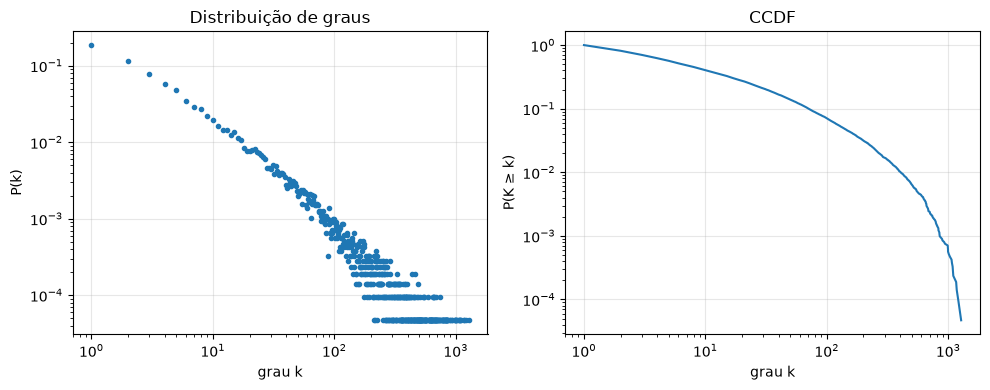

In [4]:
distribuicao = distribuir_graus(graus)
ccdf = calcular_ccdf(distribuicao)
figura_graus = plotar_distribuicao_graus(distribuicao, ccdf)
salvar_figura(figura_graus, DIR_IMAGENS / "parte1_distribuicao_graus")

A distribuição mostra muitos produtos com poucos vizinhos e poucos produtos com grau alto. No gráfico em escala logarítmica, o trecho inicial se aproxima de uma reta, mas a parte dos graus mais altos cai mais rápido.

Esse formato sugere uma concentração de ligações em poucos produtos, mas **não basta para afirmar que a distribuição segue uma lei de potência**. Na questão 2 da Parte III, vamos ajustar uma lei de potência aos dados e comparar esse ajuste com outra distribuição, a lognormal.

O tratamento dos dados também deve ser considerado nessa análise. Na preparação dos dados, limitamos a 50 a quantidade de jogos por usuário. Esse limite pode afetar as ligações e os graus do grafo final.

## 4. Triângulos e clusterização

Um triângulo aparece quando três vértices estão ligados entre si. Para cada vértice $v$, contamos quantas ligações existem entre seus vizinhos. Chamamos essa quantidade de $t(v)$.

O código faz essa contagem comparando os conjuntos de vizinhos. Como cada triângulo é contado uma vez em cada um dos seus três vértices, o total é:

$$T = \frac{\sum_v t(v)}{3}$$

O coeficiente de clusterização de um vértice indica quanto seus vizinhos estão ligados entre si:

$$C_v = \frac{2t(v)}{k_v(k_v-1)}$$

Se o grau $k_v$ for menor que 2, usamos $C_v = 0$. Depois, calculamos a média desses coeficientes. Usamos nossa implementação para obter os resultados e o igraph para conferir.

In [5]:
inicio = time.perf_counter()
triangulos = contar_triangulos_por_vertice(grafo.adjacencia)
clusterizacao = calcular_clusterizacao_local(grafo.adjacencia, triangulos)
total_triangulos = sum(triangulos.values()) // 3
clusterizacao_media = sum(clusterizacao.values()) / n
print(f"próprio: T = {total_triangulos:,}  C médio = {clusterizacao_media:.5f}  "
      f"({time.perf_counter() - inicio:.1f} s)")
referencia = conferir_clusterizacao(grafo.adjacencia)
print(f"igraph:  T = {referencia.triangulos:,}  C médio = {referencia.clusterizacao_media:.5f}")
assert total_triangulos == referencia.triangulos
assert abs(clusterizacao_media - referencia.clusterizacao_media) < 1e-9

próprio: T = 4,389,728  C médio = 0.32453  (2.7 s)


igraph:  T = 4,389,728  C médio = 0.32453


Nossa implementação encontrou **4.389.728 triângulos** e uma clusterização média de **0,32453**. A conferência com o igraph passou: a contagem de triângulos foi igual e a diferença entre as médias ficou abaixo de $10^{-9}$.

Como referência, em um grafo aleatório do modelo Erdős–Rényi com o mesmo número de vértices e arestas, a clusterização esperada seria aproximadamente a densidade:

$$C_{rand} \approx \frac{\langle k\rangle}{n-1} \approx 1{,}4\times10^{-3}$$

A clusterização do nosso grafo é cerca de **230 vezes** esse valor. Isso indica que há mais ligações entre vizinhos do que nessa referência aleatória.

Parte desse resultado pode vir da forma como montamos o grafo. Produtos avaliados pelo mesmo usuário ganham ligações entre si na projeção inicial. Depois, o filtro mantém apenas as ligações com pelo menos dois avaliadores em comum. Na Parte III, vamos comparar o resultado com um modelo aleatório que também leve em conta a relação entre usuários e produtos.

## 5. Distâncias: diâmetro, raio e caminho médio

Aqui, a distância é a quantidade de arestas do menor caminho entre dois produtos. Não usamos os pesos nesse cálculo.

- O **diâmetro** é a maior dessas distâncias.
- O **raio** é a menor distância máxima de um vértice até os demais.
- O **comprimento médio dos caminhos** é a média das distâncias entre os pares de vértices.

Usamos dois cálculos:

- **Exato, com código próprio:** uma BFS a partir de cada um dos $n$ vértices (`src/parte1/distancias.py`). A excentricidade de um vértice é a maior distância da sua BFS; o diâmetro e o raio são a maior e a menor excentricidade, e o caminho médio é a soma de todas as distâncias dividida pelos $n(n-1)$ pares ordenados. O custo é $O(n(n+m))$, cerca de $7\times10^9$ passos. Para caber em poucos minutos, o grafo vira listas de inteiros e as origens são divididas entre os núcleos do processador.
- **Conferência com o igraph:** o mesmo cálculo exato, em C, só para validar o código próprio.

In [6]:
inicio = time.perf_counter()
exatas = calcular_distancias_exatas(grafo.adjacencia, processos=os.cpu_count() or 1)
print(f"exato (código próprio, {os.cpu_count()} processos): diâmetro = {exatas.diametro}  raio = {exatas.raio}  "
      f"L = {exatas.caminho_medio:.4f}  centro = {len(exatas.centro)} vértices  ({time.perf_counter() - inicio:.0f} s)")
inicio = time.perf_counter()
referencia = medir_distancias_exatas(grafo.adjacencia)
print(f"conferência (igraph): diâmetro = {referencia.diametro}  raio = {referencia.raio}  "
      f"L = {referencia.caminho_medio:.4f}  ({time.perf_counter() - inicio:.0f} s)")
assert (exatas.diametro, exatas.raio) == (referencia.diametro, referencia.raio)
assert abs(exatas.caminho_medio - referencia.caminho_medio) < 1e-9

exato (código próprio, 12 processos): diâmetro = 13  raio = 7  L = 3.7131  centro = 285 vértices  (100 s)
conferência (igraph): diâmetro = 13  raio = 7  L = 3.7131  (78 s)


O cálculo exato com código próprio coincidiu com o igraph: diâmetro, raio e caminho médio iguais. O comprimento médio exato foi **3,7131**. Isso significa que, em média, precisamos passar por cerca de **3,7 ligações** para ir de um produto a outro na maior componente.

O **diâmetro foi 13**: esse é o maior comprimento entre os menores caminhos. O **raio foi 7**: existe pelo menos um vértice a partir do qual todos os outros podem ser alcançados em até 7 ligações.

Como comparação aproximada, a expressão $L_{rand}\approx\ln n/\ln\langle k\rangle$ dá cerca de **2,9** para uma referência aleatória. Os caminhos curtos e a clusterização alta são indícios de small-world. Vamos verificar essa hipótese na questão 1 da Parte III, comparando o grafo com modelos aleatórios.

## 6. Visualização

Mostrar os mais de 21 mil vértices de uma vez dificulta a leitura. Por isso, desenhamos apenas os **300 produtos de maior grau**, mantendo as ligações que existem entre eles. Esse recorte é um subgrafo induzido.

No desenho:

- a cor indica a plataforma;
- o tamanho indica o grau do produto na maior componente completa;
- a posição é calculada pelo algoritmo Fruchterman–Reingold, que usa as ligações e seus pesos para organizar os vértices;
- os dez produtos de maior grau recebem rótulos.

Também fixamos a semente do algoritmo para repetir a organização do desenho.

núcleo: 300 vértices, 20,347 arestas


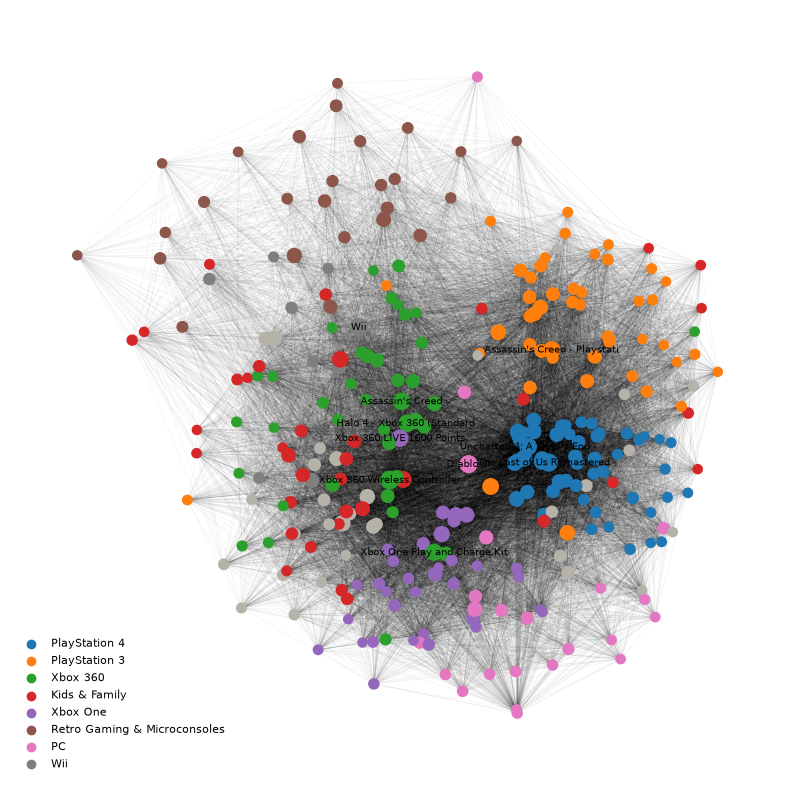

In [7]:
nucleo = set(sorted(graus, key=graus.__getitem__, reverse=True)[:300])
pesos_nucleo = restringir_arestas(grafo.pesos, nucleo)
print(f"núcleo: {len(nucleo)} vértices, {len(pesos_nucleo):,} arestas")
figura_nucleo = desenhar_subgrafo(pesos_nucleo, grafo.jogos, graus, config.SEED)
salvar_figura(figura_nucleo, DIR_IMAGENS / "parte1_nucleo_300")

O recorte tem **300 vértices e 20.347 arestas**. Na visualização, vemos regiões com produtos da mesma plataforma, como PS4, PS3, Xbox 360, Xbox One e PC. A plataforma define apenas a cor: ela não é usada para calcular a posição dos vértices.

Produtos de grau alto, como o controle do Xbox 360, Diablo III e The Last of Us, aparecem em regiões centrais do desenho. Isso ajuda a visualizar suas várias ligações, mas a posição no desenho, sozinha, não prova que eles sejam pontes entre grupos.

As categorias “Retro Gaming & Microconsoles” e “Kids & Family” reúnem produtos de diferentes plataformas. Por isso, as cores são uma indicação geral. Elas não alteram as ligações do grafo.

Também é importante lembrar que esse desenho mostra apenas os produtos de maior grau. Ele não representa todos os detalhes da maior componente.

## 7. Resumo das medidas

A seguir, reunimos as medidas calculadas e indicamos o método usado em cada uma. A contagem de componentes considera o grafo antes de selecionar a maior componente; as demais medidas numéricas se referem à maior componente.

In [8]:
medidas = [
    ["número de vértices (LCC)", n],
    ["número de arestas (LCC)", m],
    ["grau mínimo", resumo_graus.minimo],
    ["grau máximo", resumo_graus.maximo],
    ["grau médio", round(resumo_graus.media, 4)],
    ["força média", round(resumo_forcas.media, 4)],
    ["densidade", f"{densidade:.4e}"],
    ["número de componentes (backbone)", total_componentes],
    ["tamanho da LCC", max(tamanhos)],
    ["diâmetro", exatas.diametro],
    ["raio", exatas.raio],
    ["caminho médio L (exato)", round(exatas.caminho_medio, 4)],
    ["clusterização média", round(clusterizacao_media, 5)],
    ["triângulos", total_triangulos],
]
status = [
    ["Número de vértices", "sim", "exato, contagem", "-"],
    ["Número de arestas", "sim", "exato, contagem", "-"],
    ["Grau mínimo, máximo e médio", "sim", "exato, código próprio", "-"],
    ["Distribuição de graus", "sim", "exato, histograma e CCDF", "-"],
    ["Densidade", "sim", "exato, 2m/(n(n-1))", "-"],
    ["Número de componentes conexas", "sim", "exato, BFS próprio", "no backbone antes da LCC"],
    ["Tamanho de cada componente", "sim", "exato, BFS próprio", "no backbone antes da LCC"],
    ["Diâmetro", "sim", "exato, BFS própria de todos os vértices", "conferido com igraph"],
    ["Raio", "sim", "exato, BFS própria de todos os vértices", "conferido com igraph"],
    ["Comprimento médio dos caminhos", "sim", "exato, BFS própria de todos os vértices", "conferido com igraph"],
    ["Coeficiente de clusterização médio", "sim", "exato, código próprio", "conferido com igraph"],
    ["Número de triângulos", "sim", "exato, código próprio", "conferido com igraph"],
    ["Visualização", "sim", "núcleo dos 300 maiores graus", "a LCC inteira é ilegível"],
]
with open(DIR_RESULTADOS / "parte1_medidas.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["medida", "valor"], medidas, fluxo)
with open(DIR_RESULTADOS / "parte1_status.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["medida", "computada", "metodo", "justificativa"], status, fluxo)
display(Markdown(formatar_markdown(["medida", "valor"], medidas)))
display(Markdown(formatar_markdown(["medida", "computada?", "método", "justificativa"], status)))

| medida | valor |
|---|---|
| número de vértices (LCC) | 21284 |
| número de arestas (LCC) | 320742 |
| grau mínimo | 1 |
| grau máximo | 1274 |
| grau médio | 30.1393 |
| força média | 100.0335 |
| densidade | 1.4161e-03 |
| número de componentes (backbone) | 14976 |
| tamanho da LCC | 21284 |
| diâmetro | 13 |
| raio | 7 |
| caminho médio L (exato) | 3.7131 |
| clusterização média | 0.32453 |
| triângulos | 4389728 |

| medida | computada? | método | justificativa |
|---|---|---|---|
| Número de vértices | sim | exato, contagem | - |
| Número de arestas | sim | exato, contagem | - |
| Grau mínimo, máximo e médio | sim | exato, código próprio | - |
| Distribuição de graus | sim | exato, histograma e CCDF | - |
| Densidade | sim | exato, 2m/(n(n-1)) | - |
| Número de componentes conexas | sim | exato, BFS próprio | no backbone antes da LCC |
| Tamanho de cada componente | sim | exato, BFS próprio | no backbone antes da LCC |
| Diâmetro | sim | exato, BFS própria de todos os vértices | conferido com igraph |
| Raio | sim | exato, BFS própria de todos os vértices | conferido com igraph |
| Comprimento médio dos caminhos | sim | exato, BFS própria de todos os vértices | conferido com igraph |
| Coeficiente de clusterização médio | sim | exato, código próprio | conferido com igraph |
| Número de triângulos | sim | exato, código próprio | conferido com igraph |
| Visualização | sim | núcleo dos 300 maiores graus | a LCC inteira é ilegível |

## Resumo dos resultados

Nesta parte, encontramos uma componente principal com **21.284 produtos e 320.742 ligações**. Antes de selecionar essa componente, o grafo tinha **14.976 componentes**, sendo **14.677 produtos isolados**.

Na maior componente:

- a densidade é de aproximadamente **0,14%**, então há poucas ligações em relação ao total possível;
- o grau médio é **30,14**, mas alguns produtos têm mais de mil vizinhos;
- a clusterização média é **0,32453**, com **4.389.728 triângulos**;
- o caminho médio é **3,7131**, o diâmetro é **13** e o raio é **7**.

Os resultados mostram que os graus variam bastante e que os produtos podem ser alcançados por caminhos curtos, em média. Também há muitas ligações entre vizinhos quando comparamos com a referência aleatória usada nesta parte.

Na Parte III, vamos verificar se o grafo apresenta a propriedade small-world, se os graus seguem uma lei de potência e como a rede muda quando removemos vértices. Os resultados desta parte ajudam a levantar essas questões, mas ainda não respondem aos testes de robustez.